# Customer Churn Prediction — Exploratory Notebook

This notebook walks through the churn dataset and reuses the project's own
`src/` modules rather than reimplementing logic here. It's meant for
inspection and explanation, not as the source of truth for the pipeline —
that lives in `main.py` and `src/`.

In [1]:
import sys
from pathlib import Path

# Make the project root importable when running from notebooks/
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(project_root))

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

from src.config import RAW_DATA_PATH
from src.data_loader import load_data
from src.validation import validate_raw_dataset, clean_total_charges
from src.preprocessing import prepare_features_and_target, split_data, build_pipeline
from src.train import get_candidate_models, cross_validate_models
from src.evaluate import evaluate_all_models, plot_roc_curves

sns.set_theme(style="whitegrid")
%matplotlib inline

## 1. Load and validate

In [2]:
df = load_data(RAW_DATA_PATH)
validate_raw_dataset(df)
df.shape

2026-09-13 07:28:50,623 | INFO | src.data_loader | Loaded dataset with shape (7043, 21) from /home/claude/predictive_modeling_ml/data/raw/telco_customer_churn.csv


2026-09-13 07:28:50,627 | INFO | src.validation | Raw dataset passed validation. Shape: (7043, 21)


(7043, 21)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [4]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 2. Data quality checks

In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
print("\nBlank TotalCharges (known dataset quirk):", (df["TotalCharges"] == " ").sum())

Missing values per column:
Series([], dtype: int64)

Duplicate rows: 0

Blank TotalCharges (known dataset quirk): 11


## 3. Target distribution

Churn rate: 26.5%


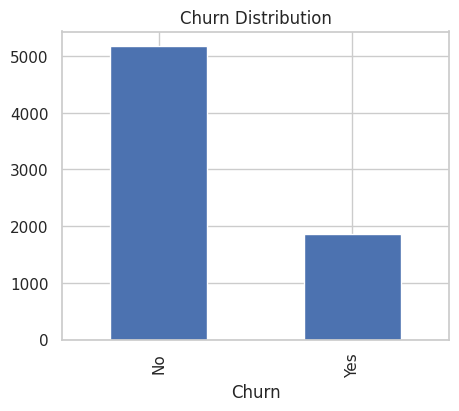

In [6]:
churn_counts = df["Churn"].value_counts()
churn_rate = (df["Churn"] == "Yes").mean()
print(f"Churn rate: {churn_rate:.1%}")

fig, ax = plt.subplots(figsize=(5, 4))
churn_counts.plot(kind="bar", ax=ax)
ax.set_title("Churn Distribution")
plt.show()

## 4. Feature relationships with churn

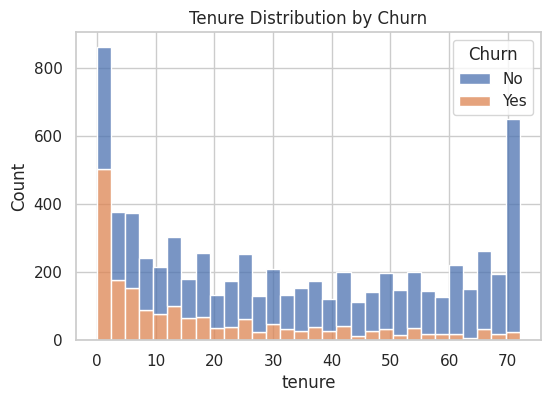

In [7]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.histplot(data=df, x="tenure", hue="Churn", multiple="stack", bins=30, ax=ax)
ax.set_title("Tenure Distribution by Churn")
plt.show()

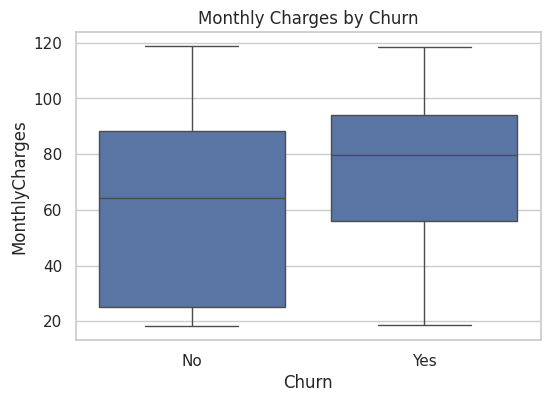

In [8]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x="Churn", y="MonthlyCharges", ax=ax)
ax.set_title("Monthly Charges by Churn")
plt.show()

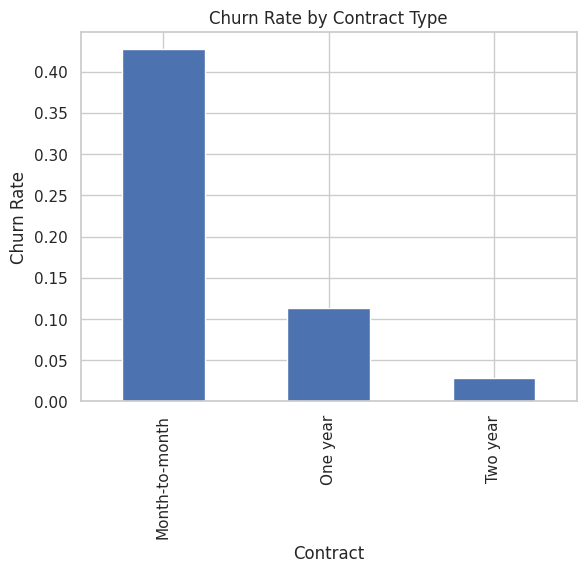

In [9]:
churn_by_contract = df.groupby("Contract")["Churn"].apply(lambda s: (s == "Yes").mean())
churn_by_contract.plot(kind="bar", title="Churn Rate by Contract Type", ylabel="Churn Rate")
plt.show()

2026-09-13 07:28:51,137 | INFO | src.validation | Filling 11 blank TotalCharges values with 0.0 (0-tenure customers).


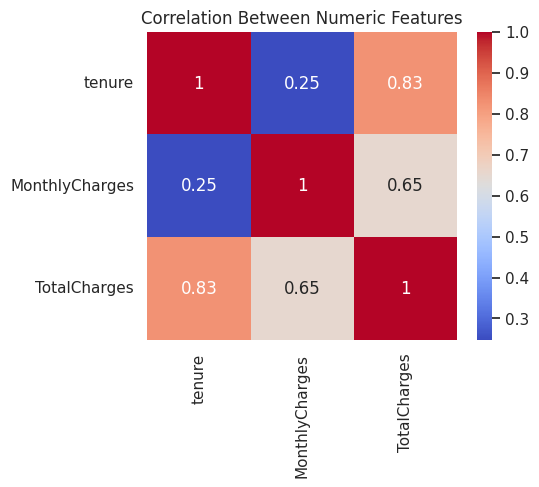

In [10]:
numeric_df = clean_total_charges(df)[["tenure", "MonthlyCharges", "TotalCharges"]]
corr = numeric_df.corr()

fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap="coolwarm", ax=ax)
ax.set_title("Correlation Between Numeric Features")
plt.show()

## 5. Preprocessing and train/test split

This reuses `prepare_features_and_target` and `split_data` from `src/preprocessing.py`
so the notebook can't drift from what training actually does.

In [11]:
X, y = prepare_features_and_target(df)
X_train, X_test, y_train, y_test = split_data(X, y)
X_train.shape, X_test.shape

2026-09-13 07:28:51,272 | INFO | src.validation | Filling 11 blank TotalCharges values with 0.0 (0-tenure customers).


2026-09-13 07:28:51,301 | INFO | src.preprocessing | Split data into train=(5634, 19) and test=(1409, 19) (churn rate train=0.265, test=0.265)


((5634, 19), (1409, 19))

## 6. Cross-validated baseline scores

In [12]:
cv_scores = cross_validate_models(X_train, y_train)
cv_scores

2026-09-13 07:28:51,669 | INFO | src.train | logistic_regression: CV ROC-AUC = 0.8454 (+/- 0.0141)


2026-09-13 07:28:52,023 | INFO | src.train | decision_tree: CV ROC-AUC = 0.8130 (+/- 0.0199)


2026-09-13 07:28:55,859 | INFO | src.train | random_forest: CV ROC-AUC = 0.8440 (+/- 0.0124)


{'logistic_regression': 0.8453830665088017,
 'decision_tree': 0.8129680203837371,
 'random_forest': 0.8440366840334953}

## 7. Train the three required models

In [13]:
pipelines = {}
for name, model in get_candidate_models().items():
    pipeline = build_pipeline(model)
    pipeline.fit(X_train, y_train)
    pipelines[name] = pipeline

list(pipelines.keys())

['logistic_regression', 'decision_tree', 'random_forest']

## 8. Evaluate and compare

In [14]:
comparison = evaluate_all_models(pipelines, X_test, y_test)
comparison

,accuracy,precision,recall,f1_score,roc_auc
model,,,,,
logistic_regression,0.738112,0.504303,0.783422,0.613613,0.841502
random_forest,0.767211,0.547131,0.713904,0.619490,0.839965
decision_tree,0.740241,0.506873,0.788770,0.617155,0.828417


In [15]:
plot_roc_curves(pipelines, X_test, y_test)
plt.show()

2026-09-13 07:28:57,201 | INFO | src.evaluate | Saved ROC curve comparison to /home/claude/predictive_modeling_ml/visualizations/roc_curves_comparison.png


## 9. Takeaways

- Logistic Regression, despite being the simplest model, is competitive with Random Forest on ROC-AUC here —
  a good reminder to always check a linear baseline before reaching for something heavier.
- `Contract` type and `tenure` are the strongest churn signals: month-to-month, low-tenure customers churn far more.
- Full training, evaluation, and model selection logic lives in `main.py` / `src/` — this notebook is for
  exploration, not the source of truth.